In [1]:
import sys; sys.path.append("..")
%load_ext autoreload
%autoreload 2
import time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
from src.data import load_data, time_split, FEATURES
from src.metrices import evaluate

df = load_data()
train, val, test = time_split(df)

X_train, y_train = train[FEATURES], train["Class"]
X_val,   y_val   = val[FEATURES],   val["Class"]

pos, neg = y_train.sum(), (y_train == 0).sum()
print("train rows:", len(train), "| val rows:", len(val))
print("frauds train / val:", pos, y_val.sum())
print("neg/pos ratio:", round(neg / pos, 1))

train rows: 170884 | val rows: 56961
frauds train / val: 360 57
neg/pos ratio: 473.7


In [2]:
k = int(len(y_val) * 0.005)
print("k =", k, "| max possible P@0.5% =", round(min(1, y_val.sum() / k), 3))

k = 284 | max possible P@0.5% = 0.201


In [3]:
xgbc = xgb.XGBClassifier(
    n_estimators=300, learning_rate=0.05, max_depth=6,
    subsample=0.8, colsample_bytree=0.8,
    scale_pos_weight=(neg / pos) ** 0.5,
    eval_metric="aucpr", tree_method="hist",
    random_state=42, n_jobs=-1,
)
t = time.time()
xgbc.fit(X_train, y_train)
print(f"trained in {time.time() - t:.1f}s")

val_scores = xgbc.predict_proba(X_val)[:, 1]
res = evaluate(y_val, val_scores)
pd.DataFrame({"XGBoost (sqrt weight)": res}).T.round(3)

trained in 3.7s


,PR_AUC,P@0.1%,R@0.1%,P@0.5%,R@0.5%,P@1.0%,R@1.0%
XGBoost (sqrt weight),0.782,0.768,0.754,0.162,0.807,0.084,0.842


In [4]:
rows = {}
for name, w in [("no weight", 1.0),
                ("sqrt weight", (neg / pos) ** 0.5),
                ("full weight", neg / pos)]:
    m = xgb.XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=6,
                          subsample=0.8, colsample_bytree=0.8,
                          scale_pos_weight=w, tree_method="hist",
                          random_state=42, n_jobs=-1)
    m.fit(X_train, y_train)
    rows[f"XGB {name}"] = evaluate(y_val, m.predict_proba(X_val)[:, 1])

weight_table = pd.DataFrame(rows).T
weight_table.round(3)

,PR_AUC,P@0.1%,R@0.1%,P@0.5%,R@0.5%,P@1.0%,R@1.0%
XGB no weight,0.785,0.768,0.754,0.162,0.807,0.081,0.807
XGB sqrt weight,0.782,0.768,0.754,0.162,0.807,0.084,0.842
XGB full weight,0.785,0.786,0.772,0.173,0.860,0.086,0.860


In [5]:
rows = []
for lr in [0.03, 0.1]:
    for depth in [3, 6]:
        m = xgb.XGBClassifier(n_estimators=300, learning_rate=lr, max_depth=depth,
                              subsample=0.8, colsample_bytree=0.8,
                              scale_pos_weight=(neg / pos) ** 0.5,
                              tree_method="hist", random_state=42, n_jobs=-1)
        m.fit(X_train, y_train)
        rows.append({"lr": lr, "depth": depth,
                     **evaluate(y_val, m.predict_proba(X_val)[:, 1])})

tune_table = pd.DataFrame(rows).sort_values("PR_AUC", ascending=False)
tune_table.round(3)

,lr,depth,PR_AUC,P@0.1%,R@0.1%,P@0.5%,R@0.5%,P@1.0%,R@1.0%
3,0.10,6,0.781,0.768,0.754,0.162,0.807,0.084,0.842
1,0.03,6,0.776,0.768,0.754,0.162,0.807,0.084,0.842
2,0.10,3,0.775,0.768,0.754,0.158,0.789,0.083,0.825
0,0.03,3,0.774,0.768,0.754,0.162,0.807,0.084,0.842


In [6]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

lr_model = make_pipeline(StandardScaler(),
                         LogisticRegression(class_weight="balanced", C=0.1, max_iter=2000))
lr_model.fit(X_train, y_train)
lr_res = evaluate(y_val, lr_model.predict_proba(X_val)[:, 1])
pd.DataFrame({"Logistic (balanced)": lr_res}).T.round(3)

,PR_AUC,P@0.1%,R@0.1%,P@0.5%,R@0.5%,P@1.0%,R@1.0%
Logistic (balanced),0.756,0.696,0.684,0.165,0.825,0.086,0.86


In [7]:
summary = pd.concat([
    pd.DataFrame({"Logistic (balanced)": lr_res}).T,
    weight_table,
]).sort_values("PR_AUC", ascending=False)
summary.round(3)

,PR_AUC,P@0.1%,R@0.1%,P@0.5%,R@0.5%,P@1.0%,R@1.0%
XGB no weight,0.785,0.768,0.754,0.162,0.807,0.081,0.807
XGB full weight,0.785,0.786,0.772,0.173,0.860,0.086,0.860
XGB sqrt weight,0.782,0.768,0.754,0.162,0.807,0.084,0.842
Logistic (balanced),0.756,0.696,0.684,0.165,0.825,0.086,0.860


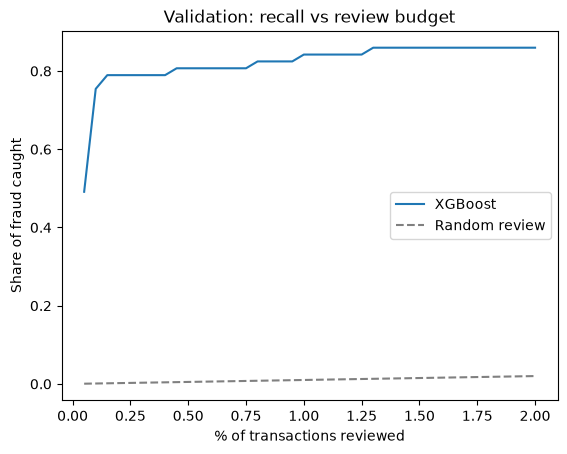

In [8]:
yv = y_val.values
order = np.argsort(-val_scores)
hits = np.cumsum(yv[order])
budgets = np.linspace(0.0005, 0.02, 40)
ks = np.maximum((budgets * len(yv)).astype(int), 1)

plt.plot(budgets * 100, hits[ks - 1] / yv.sum(), label="XGBoost")
plt.plot(budgets * 100, budgets, "--", color="gray", label="Random review")
plt.xlabel("% of transactions reviewed"); plt.ylabel("Share of fraud caught")
plt.title("Validation: recall vs review budget"); plt.legend()
plt.show()

In [9]:
import os
os.makedirs("../reports", exist_ok=True)
summary.to_csv("../reports/supervised_val_results.csv")